In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
import numpy as np
from PIL import Image
from dataset import get_dataloader
from vlm_model import VLM_for_CLEVR
from config import get_default_cfg
from torch.utils.data import DataLoader
import pickle

from vis_utils import *

/data/user_data/sjaiswa3/micromamba/envs/iprm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
cfg = get_default_cfg(mode='clevr')
#config_file = "./configs/00_m6_t9_DISTIL-roberta_full_272_feats_CLEVRH_Only.yaml" #rmam_m6_t6_red_2_wind_2.yaml"
config_file = "./configs/m6_t9.yaml" #m6_t9_redr1_16x16.yaml"
if config_file:
    cfg.merge_from_file(config_file)

In [3]:
device = torch.device(cfg.DEVICE if torch.cuda.is_available() else "cpu")

In [4]:
device

device(type='cuda')

In [5]:
net = VLM_for_CLEVR(cfg).to(device)

loading pretrained lang encoder from:  None


In [6]:
with open("/data/user_data/sjaiswa3/iprm_ckpts/ckpts/best_clevr_humans_model_clv_best.model", 'rb') as f:
#with open("/data/usrdata/shan/IPRM_ablations/m6_t9_redr1_16_16_CLEVRH_only/best_clevr_humans_model_ep_30.model", 'rb') as f:
    state = torch.load(f, map_location=device)
net.load_state_dict(state, strict=False)

_IncompatibleKeys(missing_keys=[], unexpected_keys=['lang_encoder.embeddings.position_ids'])

In [7]:
net

VLM_for_CLEVR(
  (conv): Sequential(
    (0): Dropout(p=0.15, inplace=False)
    (1): Conv2d(1024, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ELU(alpha=1.0)
    (3): Dropout(p=0.15, inplace=False)
    (4): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ELU(alpha=1.0)
  )
  (lang_encoder): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-5): 6 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_fea

In [8]:
cfg.DATALOADER.EVAL_BATCH_SIZE=32
cfg.DATALOADER.BATCH_SIZE=192

if you get lavis error, try this and 

from transformers.modeling_utils import (
    PreTrainedModel,
    # apply_chunking_to_forward,
    find_pruneable_heads_and_indices,
    prune_linear_layer,
)
from transformers.pytorch_utils import apply_chunking_to_forward


In [9]:
train_dataloader, val_dataloaders = get_dataloader(cfg, mode='clevr', use_clevr_humans= True, #cfg.USE_CLEVR_HUMANS,
                                                      clevr_train_split=cfg.CLEVR_TRAIN_SPLIT,
                                                      clevr_val_split=cfg.CLEVR_VAL_SPLIT,
                                                   train_percent=1.0,#0.002,
                                                       #use_vlm_dataloader =False#cfg.USE_VLM_DATALOADER
                                                     )
from lavis.models import load_model_and_preprocess
_, _, txt_processors = load_model_and_preprocess(name='blip_vqa', model_type='vqav2', is_eval=True, device='cpu') 
del(_)
#net.vlm_module.max_computation_steps = 6

answer vocab path:  clevr_labels_tuple.pkl
answer vocab path:  clevr_labels_tuple.pkl


/data/user_data/sjaiswa3/micromamba/envs/iprm/lib/python3.12/site-packages/fairscale/experimental/nn/offload.py:19: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  return torch.cuda.amp.custom_fwd(orig_func)  # type: ignore
/data/user_data/sjaiswa3/micromamba/envs/iprm/lib/python3.12/site-packages/fairscale/experimental/nn/offload.py:30: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  return torch.cuda.amp.custom_bwd(orig_func)  # type: ignore


In [10]:
dl = val_dataloaders[0]

In [11]:
original_data_record = dl.dataset.data#[qid]
with open("/data/user_data/sjaiswa3/iprm_datasets/clevr_feats/features/clevr_humans_and_original_vocab.pkl",'rb') as f:
    vocab = pickle.load(f)
#vocab = net.tokenizer.ids_to_tokens

In [12]:
try:
    id2w = net.tokenizer.ids_to_tokens#{v:k for k, v in vocab['word_dic'].items()}
except:
    id2w = {v:k[1:] for k,v in net.tokenizer.get_vocab().items()}
aid2w = {v:k for k, v in vocab['answer_dic'].items()}

In [13]:
from lavis.models import load_model_and_preprocess
_, _, txt_processors = load_model_and_preprocess(name='blip_vqa', model_type='vqav2', is_eval=True, device='cpu') 
del(_)
#net.vlm_module.max_computation_steps = 6

In [14]:
for val_i, val_dataloader in enumerate(val_dataloaders):
    dataloader = iter(val_dataloader)
    net.eval()
    pbar = dataloader
    with torch.no_grad():
        for i, item in enumerate(pbar):
            image, question, answer = item['images'], [txt_processors['eval'](qs) for qs in item['questions']], item['answer_ids']
            image = image.to(device)
            q_len = None
            output = net(image, question, q_len)
            if(i==0):
                break

In [15]:
b_i = 1
atts = net.vlm_module.attentions
num_mem_tokens = net.vlm_module.num_memory_tokens
num_computation_steps = net.vlm_module.max_computation_steps
num_mem_tokens, num_computation_steps, atts.keys()

(6,
 9,
 dict_keys(['text', 'image', 'inter', 'start', 'inter_mem_op', 'final_pool_attn_wt']))

Question: how many objects are the same color as the large cylinder located in the back between the two purple objects?
Prediction: 2
Ground Truth: 2


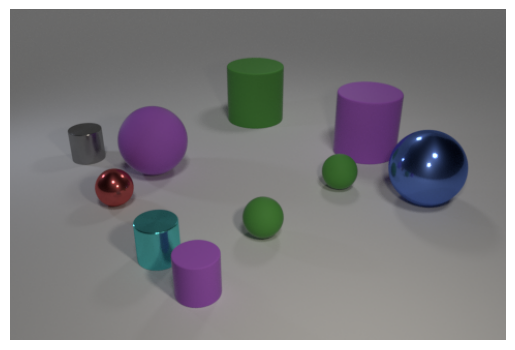

In [16]:



pred, gt_ans, og_question = output.argmax(-1)[b_i], answer[b_i].argmax(), question[b_i]
qid = item['q_ids'][b_i]
img_file = original_data_record[qid]['image_filename']#[0]
img = Image.open(f"/data/user_data/sjaiswa3/iprm_datasets/clevr/CLEVR_v1.0/images/val/{img_file}")
img = img.convert('RGB')
img_att_tokens = atts['image'].squeeze(-1).transpose(0,1)[b_i]
img_att_tokens = F.softmax(img_att_tokens, dim=2)
text_att_tokens =  atts['text'].squeeze(-1).transpose(0,1)[b_i]
text_att_tokens = F.softmax(text_att_tokens, dim=2)
mem_att_tokens =  atts['inter_mem_op'].squeeze(-1).transpose(0,1)[b_i]


#print(pred, gt_ans, og_question)c
pred_text, gt_ans_text = aid2w[int(pred)], aid2w[int(gt_ans)]
og_question_text_list = net.tokenizer.tokenize(og_question, add_special_tokens=False, return_length=True, padding=True)
og_question_text = og_question#net.tokenizer.tokenize(, add_special_tokens=False, return_length=True, padding=True)#model.tokog_question#' '.join(og_question_text_list)
print(f"Question: {og_question_text}\nPrediction: {pred_text}\nGround Truth: {gt_ans_text}")
plt.axis('off')
#plt.xlabel(f"Question:{question}")
plt.imshow(img)


In [17]:
# Process attention over time using the utility function
attention_results = process_attention_over_time(
    img, 
    text_att_tokens, 
    img_att_tokens, 
    og_question_text_list,
    vis_iterative_steps = net.vlm_module.max_computation_steps, 
    vis_parallel_ops = net.vlm_module.num_memory_tokens
)

text_atts_over_t = attention_results['text_atts_over_t']
text_atts_over_t_meaned = attention_results['text_atts_over_t_meaned']
text_atts_over_t_maxed = attention_results['text_atts_over_t_maxed']
img_atts_over_t = attention_results['img_atts_over_t']
img_atts_over_t_meaned = attention_results['img_atts_over_t_meaned']
img_atts_over_t_maxed = attention_results['img_atts_over_t_maxed']


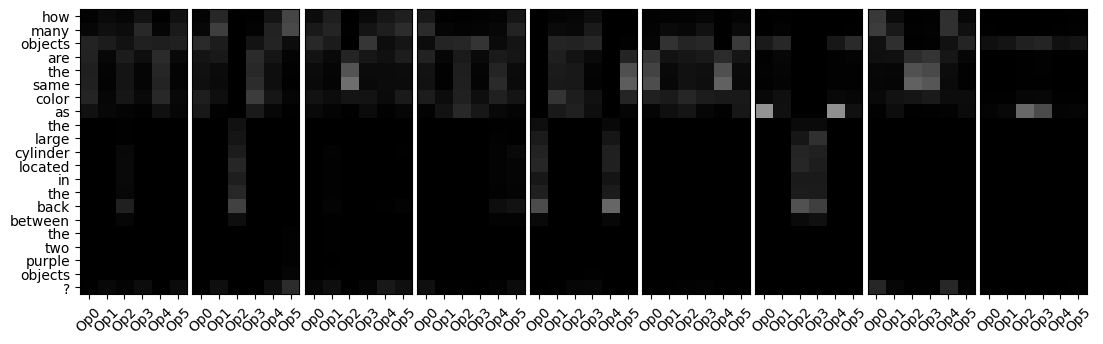

In [18]:
plot_lang_atts_across_times_together(img_atts_over_t, text_atts_over_t, figsize=(13,3.7))

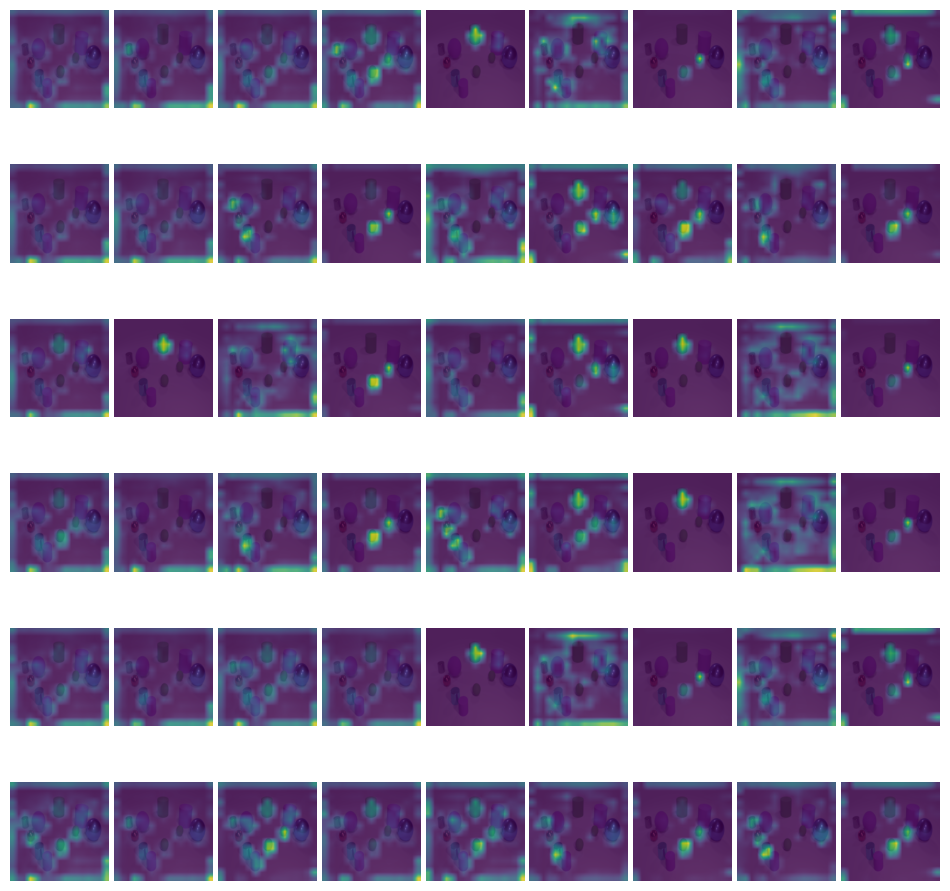

In [19]:
plot_img_atts_across_times_together(img_atts_over_t, text_atts_over_t, figsize=(12,12)) #vertical is parallel steps, horizontal is iterative steps